# <center>PTA Noise Models</center>

### <center><span style="font-family:Comic Sans MS; color:blue">Prepared by Valentina Di Marco</span></center>

<div style = 'background-color:yellow'> Before running the tutorial make a directory using your name and save a copy of Noise_models.ipynb in it </div>

In this tutorial, we will explore the main sources of noise in Pulsar Timing Arrays (PTAs) through simulations.

---

## Fantastic noise sources and where to find them (or, how to model them).

In pulsar timing, accurately searching for gravitational wave signals requires comprehensive modeling of the variations of pulsar arrival times. These variations arise from both deterministic and stochastic processes. Deterministic components—captured in the pulsar ephemerides—include effects such as the nonlinear change in the pulsar–Earth distance, relativistic propagation effects within the Solar System, and within the binary system if the pulsar has a companion.


Stochastic contributions can be broadly categorized into two types: 
1. **temporally uncorrelated (white noise)** 
2. **temporally correlated (red noise)**

**White noise** sources primarily include radiometer noise (due to the radio telescope) and intrinsic pulse-to-pulse shape variations, commonly known as pulse jitter.

**Red noise**, on the other hand, is subdivided into **chromatic** and **achromatic** components. Chromatic red noise depends on observing radio frequency, while achromatic red noise does not. 

The achromatic component—often called timing noise or spin noise—is believed to originate from irregularities in the neutron star’s rotation.

The most significant source of chromatic red noise is due to **dispersion-measure (DM)** variations, caused by changes in the ionized plasma column density along the pulsar-Earth line of sight. Unmodeled variations in the **solar wind** also manifest themselves as excess DM.
Other chromatic red noise processes have also been identified, including band-dependent (specific to radio bands) and system-dependent (linked to the telescope’s backend) contributions. The exact origins of these components remain uncertain, though they are hypothesized to result from either propagation effects in the interstellar medium or instrument-related systematics.

If you want to know more about the noise in pulsar timing see this paper https://academic.oup.com/mnras/article/502/1/478/5957533.

A vector of residuals of lenght $N_{TOA}$ can be modeled mathematically as the sum of  several deterministic and stochastic sources as follows $$\delta t = M\epsilon + Fa + F_{DM}a_{DM} + Uj + n$$

- $M\epsilon$ describes small deterministic trends due to timing model subtraction. 
- $Fa$ models the achromatic red noise via a Fourier decomposition.
- $F_{DM}a_{DM}$ models the chromatic red noise due to dispersion measure via a Fourier decomposition (and similarly we can add other sources of chromatic noise). Here $F$ is the Fourier design matrix that corresponds to columns of alternating sines and cosines for each frequency evaluated at the different observation times.
- $Uj$ describes noise that is uncorrelated in time but completely correlated between TOAs obtained at different frequencies measured simultaneously (like jitter).
- $n$ describes  a Gaussian white noise process that characterizes time, and  frequency independent random noise left in the data.

**The distribution of the white noise** is given by
$$p(n)=\frac{\exp(-\frac{1}{2} n^{T}N^{-1}n)}{\sqrt{det(2 \pi N)}}$$
where
$$N=E^2(W+Q^2 I)$$

is a $N_{TOA}\times N_{TOA}$ matrix, E is the **EFAC** parameter Q is the **EQUAD** parameter, W is a diagonal matrix of uncertainties ($\sigma^2 I$) and $I$ is the identity matrix.

The distribution of the noise correlated in radio frequency but not in time, are also modelled as Gaussian.

$$p(j)=\frac{\exp(-\frac{1}{2} j^{T}J^{-1}j)}{\sqrt{det(2 \pi J)}}$$

where $J = \text{ECORR} \; I$ is a diagonal matrix and the **ECORR** parameter describes the variance of the jitter-like correlated noise for each observing backend.

**The distribution of the timing noise** is also modelled as Gaussian

$$p(a)=\frac{\exp(-\frac{1}{2} a^{T}\varphi^{-1}a)}{\sqrt{det(2 \pi \varphi)}}$$

were $\varphi$ is a diagonal matrix in which every element of the diagonal is parametrised as a power law

$$\varphi_n = \frac{1}{T} PSD = \frac{1}{T}\frac{A^2}{12\pi^2}\Big(\frac{f_n}{f_{ref}}\Big)^{-\gamma}$$

were T is the total observation time, PSD is the Power Spectral Density, A is the amplitude  of the red noise, $\gamma$ is the spectral index of the  red noise, $f_{ref}$ is the reference frequency of $1 yr^{−1}$, and $f_n$ is  the nth Fourier frequency.

**The distribution of dispersion measure noise** (and other chromatic noise processes) is again modelled as Gaussian. Here $F_{DM}$ is related to the Fourier design matrix $F$ via

$$F_{DM} = F \times 1/(K\nu^{\beta}_{i})$$

were $\nu$ is the radio frequency, $K$ is a dispersion constant, and $\beta$ is the chromaticity index which is 2 for dispersion measure. 

Pulse arrival times are affected by chromatic influences which can introduce delays with a radio frequency dependence different from $∼ 1/\nu^{2}$. 

If you want to know more see appendix C of this paper https://iopscience.iop.org/article/10.1088/0004-637X/813/1/65. 

A gravitational wave would also induce a common red noise signal in the residual which is modelled as a power law

---

Now that we know more about these sources of noise, we can start model them and plot them to see what they look like in our residuals. 

let's first install the modules we need

In [4]:
# these first two lines are a jupyter notebook thing, if you want to write your script you will not need this.
# inline ensures Matplotlib plots are displayed inline within the notebook.
# retina improves resolution of figures.
%matplotlib inline
%config InlineBackend.figure_format = 'retina' 

# import packages
import numpy as np
import libstempo as T
import libstempo.toasim as LT
import libstempo.plot as LP
import matplotlib.pyplot as plt
import scipy.constants as sc
import math
import os

/fred/oz005/users/pulsar_workshop/valentina2/.conda/envs/ent15y/lib/python3.9/site-packages/numpy/core/getlimits.py:500: UserWarning: The value of the smallest subnormal for <class 'numpy.float64'> type is zero.
  setattr(self, word, getattr(machar, word).flat[0])
/fred/oz005/users/pulsar_workshop/valentina2/.conda/envs/ent15y/lib/python3.9/site-packages/numpy/core/getlimits.py:89: UserWarning: The value of the smallest subnormal for <class 'numpy.float64'> type is zero.
  return self._float_to_str(self.smallest_subnormal)
/fred/oz005/users/pulsar_workshop/valentina2/.conda/envs/ent15y/lib/python3.9/site-packages/numpy/core/getlimits.py:500: UserWarning: The value of the smallest subnormal for <class 'numpy.float32'> type is zero.
  setattr(self, word, getattr(machar, word).flat[0])
/fred/oz005/users/pulsar_workshop/valentina2/.conda/envs/ent15y/lib/python3.9/site-packages/numpy/core/getlimits.py:89: UserWarning: The value of the smallest subnormal for <class 'numpy.float32'> type is z

We now need to take some data from a real pulsar. Specifically, we need a **.par** file and a **.tim** file. The .par file is contains a set of parameters used to construct a timing model of the pulsar. The .tim file is an ascii file, with columns describing relevant information about the TOAs. <mark>Libstempo</mark> is Python wrapper around the <mark>tempo2</mark> pulsar timing package (makes simulating pulsars easier).
You will need to specify a path to your directory.

In [5]:
datadir = '/fred/oz005/users/pulsar_workshop/valentina2/PTA_tutorials/data/'

We can have a look at the .tim file. The second column specifies the radio frequency in MHz and the third column shows the time of arrivals in MJD; notice the incredibly high precision.

In [6]:
with open(datadir + "J0437-4715.tim", "r") as file:
    for _ in range(10):  # Read first 10 lines
        print(file.readline().strip())

FORMAT 1
MODE 1
0 3100.00000000 49999.99999999996840572 0.04220 pks -or pks -sched sched_similar_regsamp -tobs 600 -pn 0
1 1400.00000000 49999.99999998490493880 0.05520 pks -or pks -sched sched_similar_regsamp -tobs 3100 -pn -1
2 600.00000000 50000.00000000629626129 0.14100 pks -or pks -sched sched_similar_regsamp -tobs 1400 -pn -5
3 3100.00000000 50025.00000000106258469 0.04220 pks -or pks -sched sched_similar_regsamp -tobs 600 -pn 375170084
4 1400.00000000 50024.99999998599904671 0.05520 pks -or pks -sched sched_similar_regsamp -tobs 3100 -pn 375170083
5 600.00000000 50025.00000000739461825 0.14100 pks -or pks -sched sched_similar_regsamp -tobs 1400 -pn 375170079
6 3100.00000000 50049.99999997560862752 0.04220 pks -or pks -sched sched_similar_regsamp -tobs 600 -pn 750336071
7 1400.00000000 50050.00000002718138603 0.05520 pks -or pks -sched sched_similar_regsamp -tobs 3100 -pn 750336071


We can also have a look at the .par file. For more information on .par files and .tim files and in general on Tempo2, see https://www.jb.man.ac.uk/research/pulsar/Resources/tempo2_manual.pdf

In [7]:
with open(datadir + "J0437-4715.par", "r") as file:
    content = file.read()
print(content)

PSRJ           J0437-4715
RAJ            04:37:15.8146878            
DECJ           -47:15:08.62242             
F0             173.68794618475574358     1  2.9049884029276214088e-13
F1             -1.7283187296320382084e-15 1  1.5041073290473418631e-21
PEPOCH         52005                       
POSEPOCH       52005                       
DMEPOCH        53211                       
DM             2.6440400000000000001       
PMRA           121.43954                   
PMDEC          -71.480479999999999997      
PX             6.6503476597625900001       
SINI           0                           
BINARY         T2
PB             5.74104646166442            
T0             52009.852429760500002       
A1             3.3666970782369699999       
OM             1.22244717975605            
ECC            1.91796977385e-05           
PBDOT          3.73339685609e-12           
OMDOT          0.0160036205                
M2             0.25378512742869600001      
START          49999.99

Now we will define some functions and units. Libstempo can only simulate some sources of noise directly, for other sources of noise, like solar wind and chromatic noise, we need to define some functions. Just run this cell and don't worry about it.

In [8]:
### Units
day = 24 * 3600 # Days in seconds
year = 365.25 * day # Year in seconds

AU = sc.astronomical_unit
c = sc.speed_of_light
pc = sc.parsec
AU_light_sec = AU/c
AU_pc = AU/pc

########################
### Functions definition
########################

### Dispersion mesure noise
def add_dm(psr, A, gamma, idx=-2, components=30, seed=None):
    """Add dispersion measure noise variations with P(f) = A^2 / (12 pi^2) (f year)^-gamma,
    using `components` Fourier bases.
    Optionally take a pseudorandom-number-generator seed."""    

    if seed is not None:
        np.random.seed(seed)

    t = psr.toas()
    fref = 1400
    v = (psr.freqs / fref)**idx

    minx, maxx = np.min(t), np.max(t)
    x = (t - minx) / (maxx - minx)
    T = (day / year) * (maxx - minx)

    size = 2 * components
    F = np.zeros((psr.nobs, size), "d")
    f = np.zeros(size, "d")

    for i in range(components):
        F[:, 2 * i] = np.cos(2 * math.pi * (i + 1) * x)
        F[:, 2 * i + 1] = np.sin(2 * math.pi * (i + 1) * x)

        f[2 * i] = f[2 * i + 1] = (i + 1) / T

    norm = A**2 * year**2 / (12 * math.pi**2 * T) 
    prior = norm * f ** (-gamma)

    y = np.sqrt(prior) * np.random.randn(size)
    psr.stoas[:] += (1.0 / day) * v * np.dot(F, y)

### Chromatic noise
def add_ch(psr, A, gamma, idx=-4, components=30, seed=None):
    """Add chromatic noise variations with P(f) = A^2 / (12 pi^2) (f year)^-gamma,
    using `components` Fourier bases.
    Optionally take a pseudorandom-number-generator seed."""    

    if seed is not None:
        np.random.seed(seed)

    t = psr.toas()
    fref = 1400
    v = (psr.freqs / fref)**idx

    minx, maxx = np.min(t), np.max(t)
    x = (t - minx) / (maxx - minx)
    T = (day / year) * (maxx - minx)

    size = 2 * components
    F = np.zeros((psr.nobs, size), "d")
    f = np.zeros(size, "d")

    for i in range(components):
        F[:, 2 * i] = np.cos(2 * math.pi * (i + 1) * x)
        F[:, 2 * i + 1] = np.sin(2 * math.pi * (i + 1) * x)

        f[2 * i] = f[2 * i + 1] = (i + 1) / T

    norm = A**2 * year**2 / (12 * math.pi**2 * T) 
    prior = norm * f ** (-gamma)

    y = np.sqrt(prior) * np.random.randn(size)
    psr.stoas[:] += (1.0 / day) * v * np.dot(F, y)

### Solar wind
def add_sw(psr, A, gamma, components=30, seed=None):
    """Add Solar wind variations with P(f) = A^2 / (12 pi^2) (f year)^-gamma,
    using `components` Fourier bases. 
    The electron density at 1 AU distance (nearth) is 1.0
    Optionally take a pseudorandom-number-generator seed."""    

    if seed is not None:
        np.random.seed(seed)

    t = psr.toas()

    theta, R_earth = theta_impact(psr.earth_ssb, psr.sun_ssb, psr.psrPos)
    dt_sol_wind = (4.148808e3 /(psr.freqs**2))*dm_solar(1.0, theta, R_earth)

    minx, maxx = np.min(t), np.max(t)
    x = (t - minx) / (maxx - minx)
    T = (day / year) * (maxx - minx)

    size = 2 * components
    F = np.zeros((psr.nobs, size), "d")
    f = np.zeros(size, "d")

    for i in range(components):
        F[:, 2 * i] = np.cos(2 * math.pi * (i + 1) * x)
        F[:, 2 * i + 1] = np.sin(2 * math.pi * (i + 1) * x)

        f[2 * i] = f[2 * i + 1] = (i + 1) / T

    norm = A**2 * year**2 / (12 * math.pi**2 * T)
    prior = norm * f ** (-gamma)

    y = np.sqrt(prior) * np.random.randn(size)
    psr.stoas[:] += (1.0 / day) * dt_sol_wind * np.dot(F, y)

def theta_impact(earthssb,sunssb,pos_t):
    """Computes the solar impact angle"""
    earth = earthssb[:,:3]
    sun = sunssb[:,:3]
    pulsar = pos_t[:,:3]
    earthsun = earth - sun
    R_earth = np.sqrt(np.einsum('ij,ij->i', earthsun, earthsun))
    Re_cos_theta_impact = np.einsum('ij,ij->i', earthsun, pulsar)
    theta = np.arccos(-Re_cos_theta_impact / R_earth)
    return theta, R_earth

def _dm_solar_close(n_earth, r_earth):
    return (n_earth * AU_light_sec * AU_pc / r_earth)

def _dm_solar(n_earth, theta, r_earth):
    return ((np.pi - theta) *
            (n_earth * AU_light_sec * AU_pc
             / (r_earth * np.sin(theta))))

def dm_solar(n_earth, theta, r_earth):
    """
    Calculates Dispersion measure due to 1/r^2 solar wind density model.
    ::param :n_earth Solar wind proto/electron density at Earth (1/cm^3)
    ::param :theta: angle between sun and line-of-sight to pulsar (rad)
    ::param :r_earth :distance from Earth to Sun in (light seconds).
    See You et al. 2007 for more details.
    """
    return np.where(np.pi - theta >= 1e-5,
                    _dm_solar(n_earth, theta, r_earth),
                    _dm_solar_close(n_earth, r_earth))

Now we load a single-pulsar object. Doing this will automatically run the tempo2 fit routine once.

In [9]:
base_psr = T.tempopulsar(parfile=datadir + 'J0437-4715.par', 
                        timfile=datadir + 'J0437-4715.tim')

Let's plot these residuals and see what they look like

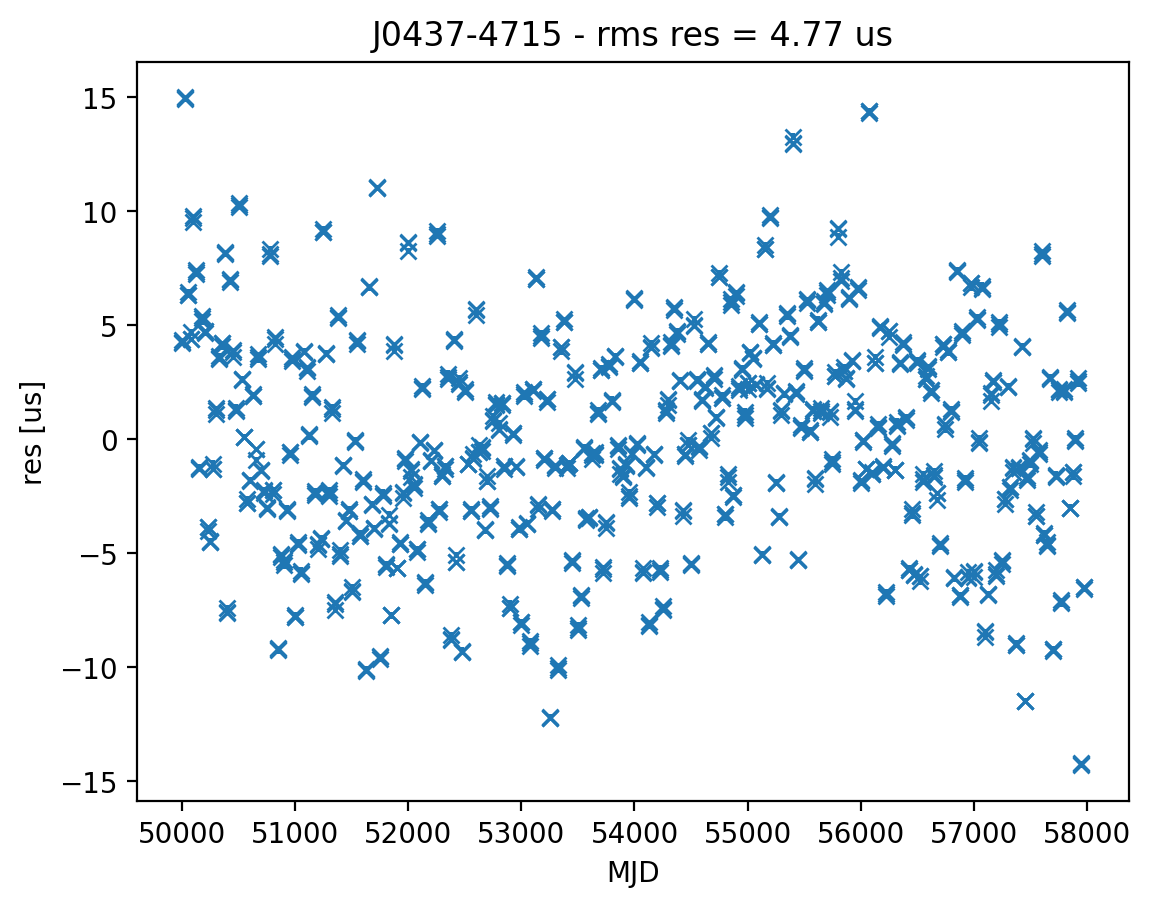

In [10]:
LP.plotres(base_psr)

<div style = 'background-color:skyblue'> What noise is dominant in this pulsar? </div>

We now remove the computed residuals from the TOAs, obtaining (in effect) a perfect realization of the deterministic timing model.

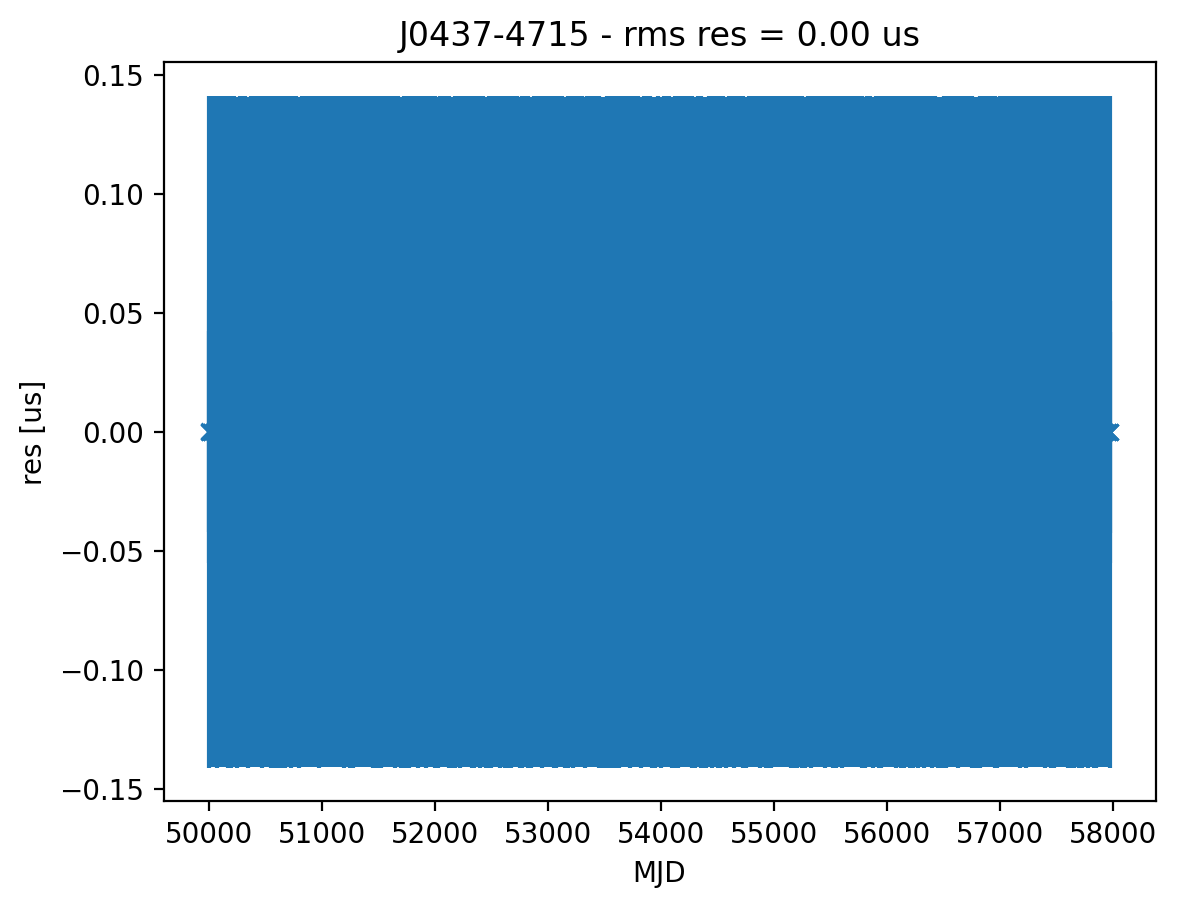

In [12]:
LT.make_ideal(base_psr)
LP.plotres(base_psr)

## Injecting noise

**white noise**: The main sources of white noise are radiometer noise and pulse-to-pulse variations of profile shape, referred to as pulse jitter.


**Radiometer noise**. During each data-taking session—which can last from a few minutes to several hours, depending on the telescope—the observed pulses are first de-dispersed (corrected for delays caused by the interstellar medium) and then folded (stacked based on the pulsar’s spin period to produce an averaged pulse shape). This averaged profile is compared to a long-term pulse template to determine the pulse’s time of arrival (TOA).

The standard uncertainties on TOAs (the error bars) come from this template-matching step and reflect only the uncertainty in the fit. However, not all sources of error are captured in this process. To account for that, we apply a correction called the Extra FACtor (<mark>EFAC</mark>), which scales the reported uncertainties to better reflect the actual measurement errors.

Here we add EFAC with rms amplitude equal to 1x the nominal TOA errors. If we want, we can add a seed for reproducibility.

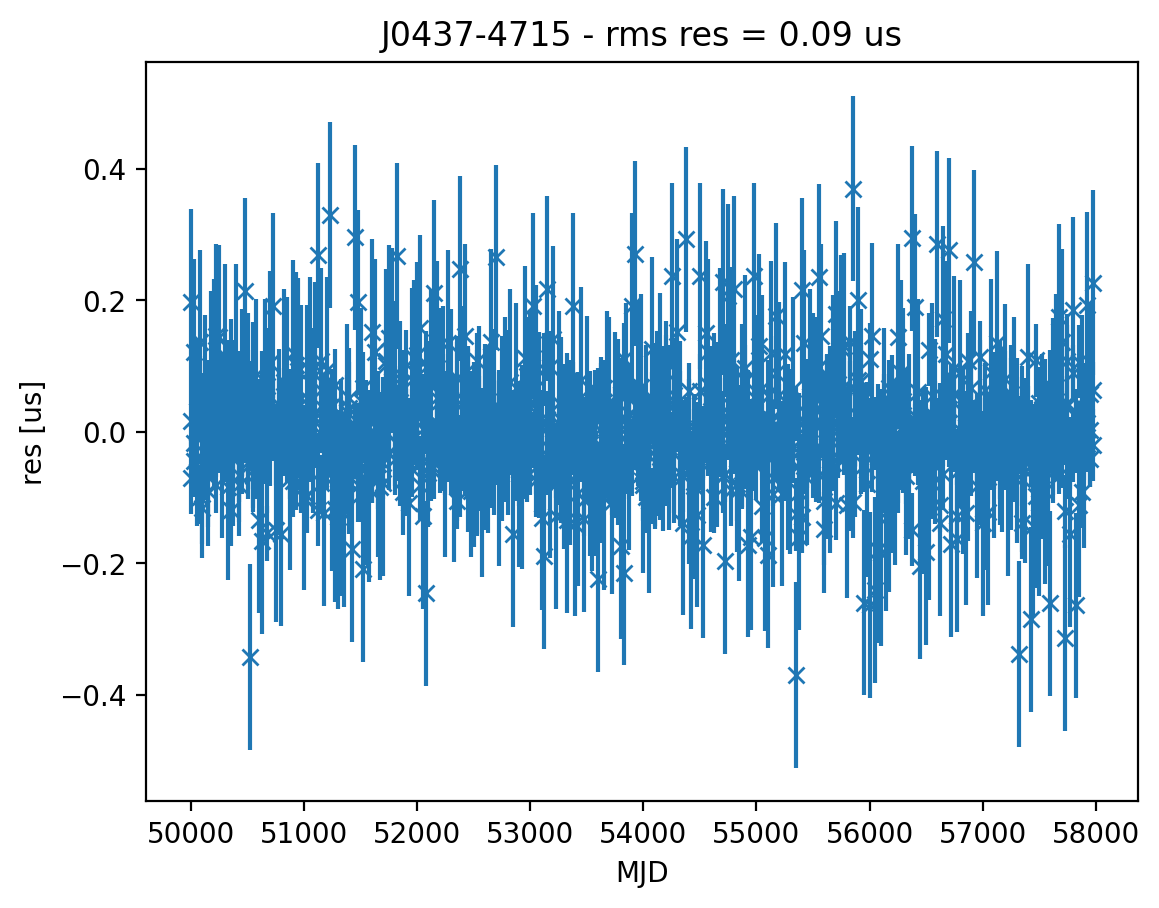

In [13]:
LT.add_efac(base_psr,efac=1.0,seed=1234)
LP.plotres(base_psr)

**jitter noise**. During an observing epoch, only a limited number of pulses are folded and matched to a standard pulse profile template. This introduces pulse phase jitter—a type of white noise caused by slight variations in the shape of the folded profile due to the limited number of pulses. These small differences create residual fluctuations relative to the template.

Although the exact amount of jitter depends on how many pulses are recorded in an epoch, this number typically stays fairly consistent over time. As a result, this noise is usually associated with specific receiver-backend systems.

Additionally, we measures multiple TOAs from nearby radio-frequency bands during the same observing epoch. Since these TOAs come from the same set of folded pulses, the jitter noise is fully correlated across those bands. This gives rise to a noise component called Extra Correlated (<mark>ECORR</mark>) white noise—it’s uncorrelated between different epochs but fully correlated within bands recorded during the same epoch.

Here we going to show what it would be like to have only jitter.

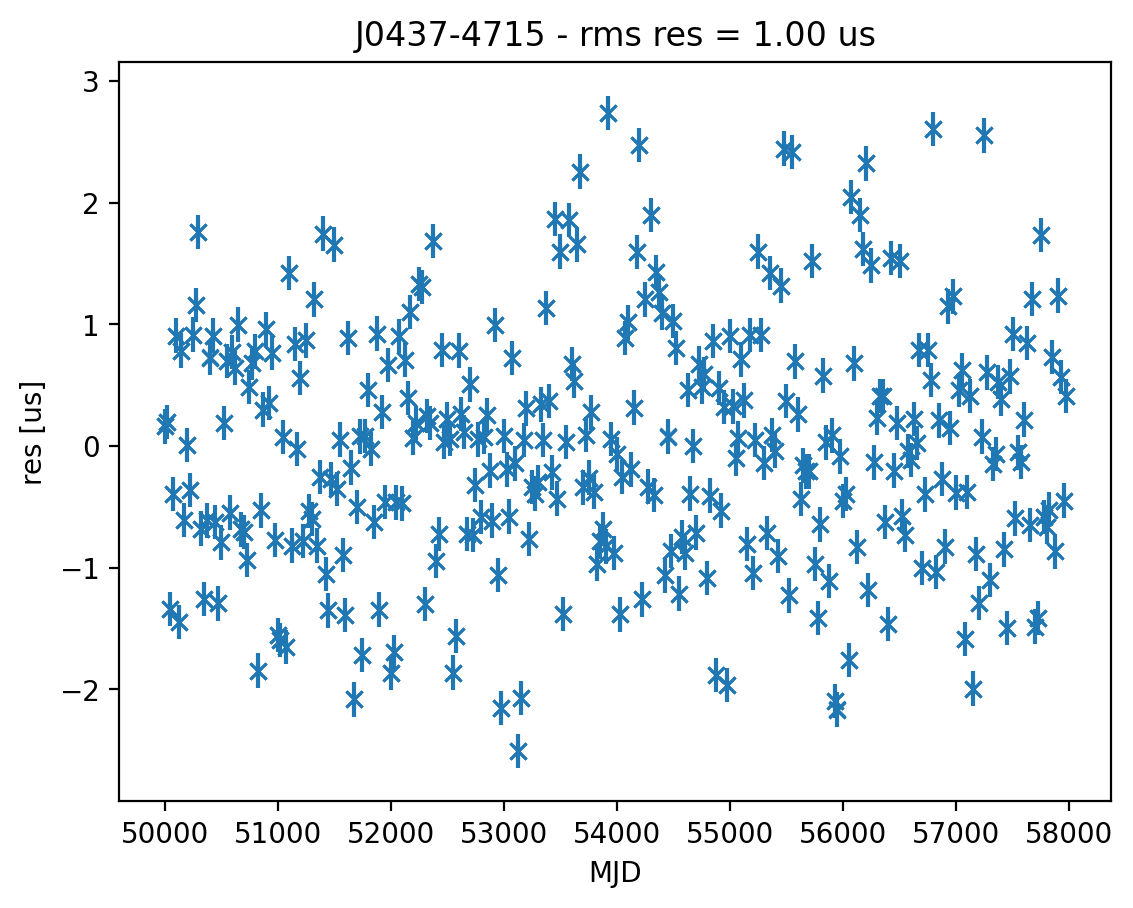

In [14]:
LT.make_ideal(base_psr)
LT.add_jitter(base_psr,1e-6)
LP.plotres(base_psr)

Sometimes, there are extra sources of white noise unrelated to radiometer noise—for example, due to instrumental effects. To account for additional non-multiplicative corrections to the TOA uncertainties, we include an Extra QUADrature (EQUAD) noise term

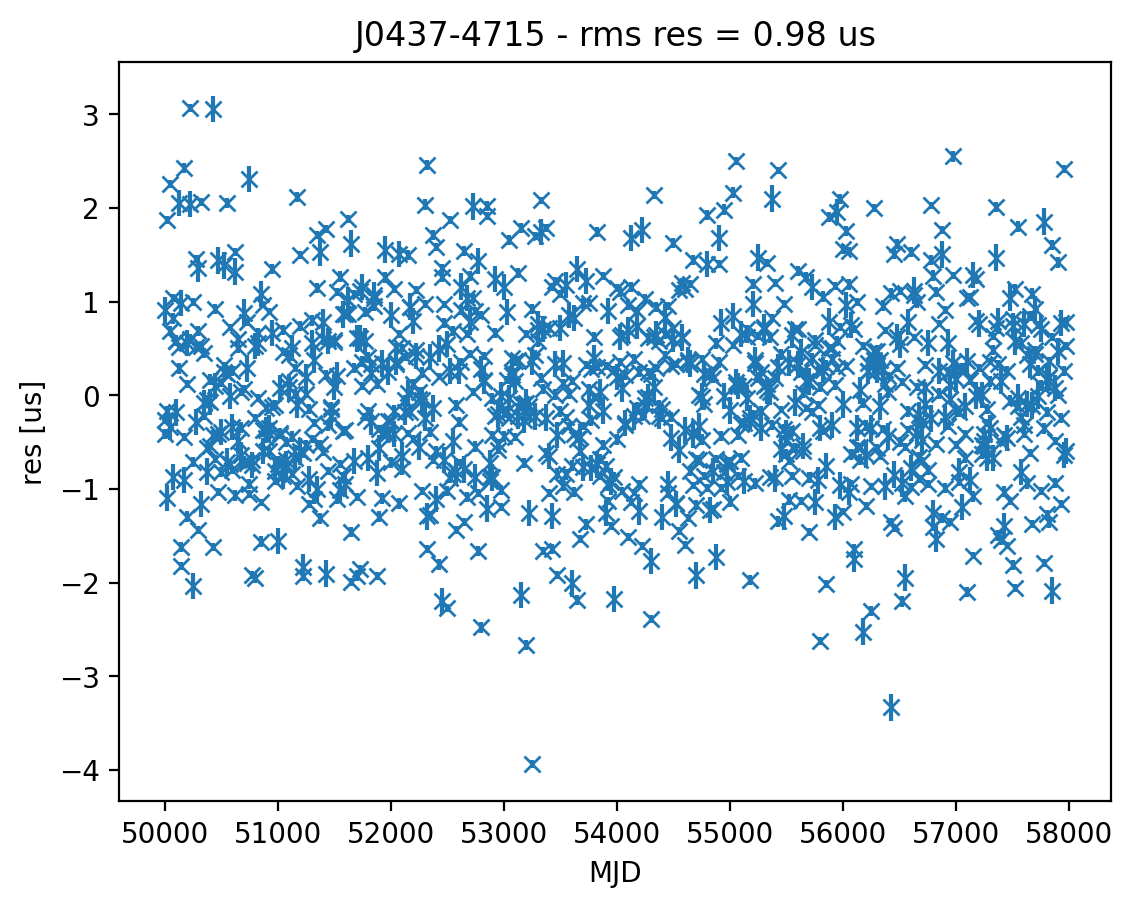

In [15]:
LT.make_ideal(base_psr)
LT.add_equad(base_psr,1e-6)
LP.plotres(base_psr)

**Timing noise** Let's now put all the sources of white noise back in the pulsar and then inject also achromatic red noise (timing noise).

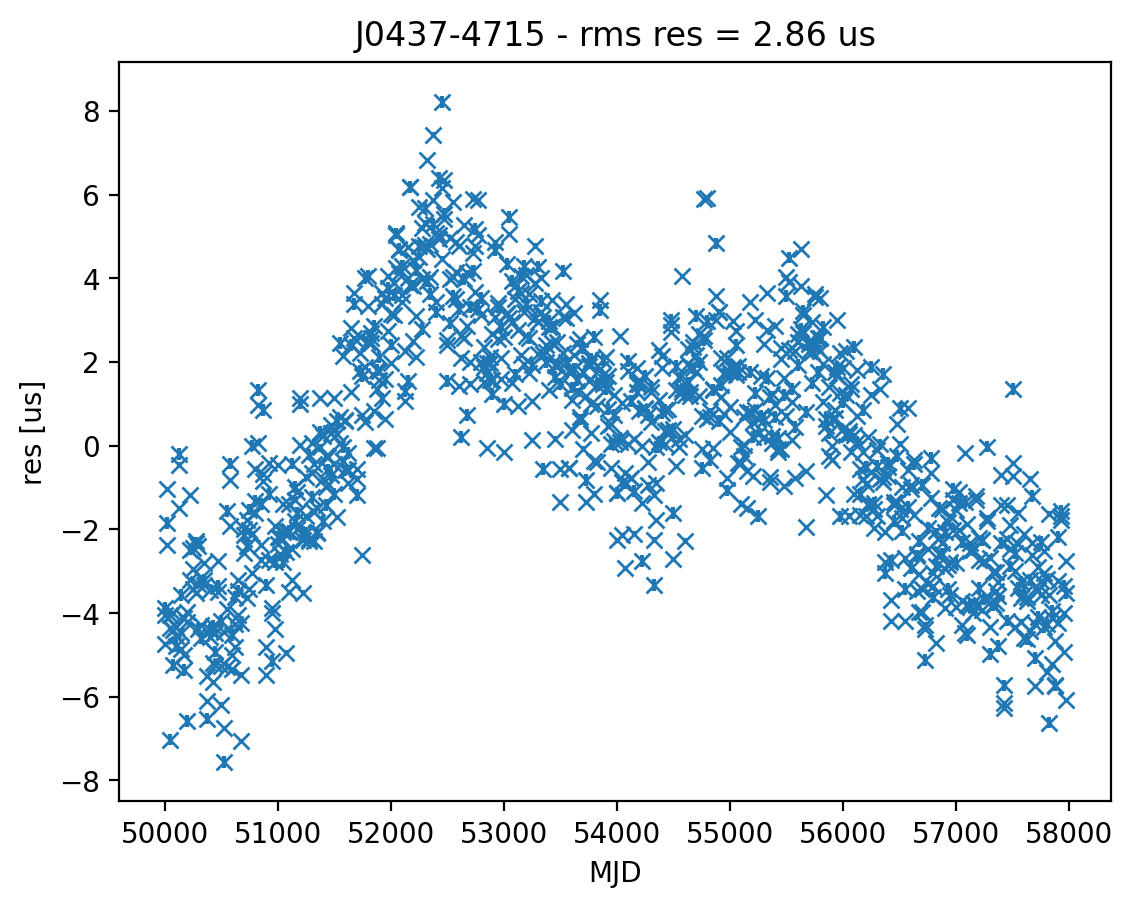

In [16]:
LT.make_ideal(base_psr)
LT.add_efac(base_psr,efac=1.0)
LT.add_jitter(base_psr,1e-6)
LT.add_equad(base_psr,1e-6)
# Simulating timing noise
LT.add_rednoise(base_psr,7e-14,2.5)
LP.plotres(base_psr)

Try now to simulate a pulsar having only efac and timing noise. use the same parameters as we have used in the above cell as well as the same seed

<div style = 'background-color:skyblue'> How do the residual look with only efac and red noise? </div>

**Dispersion Measure** Let's see how dispersion measure looks like.

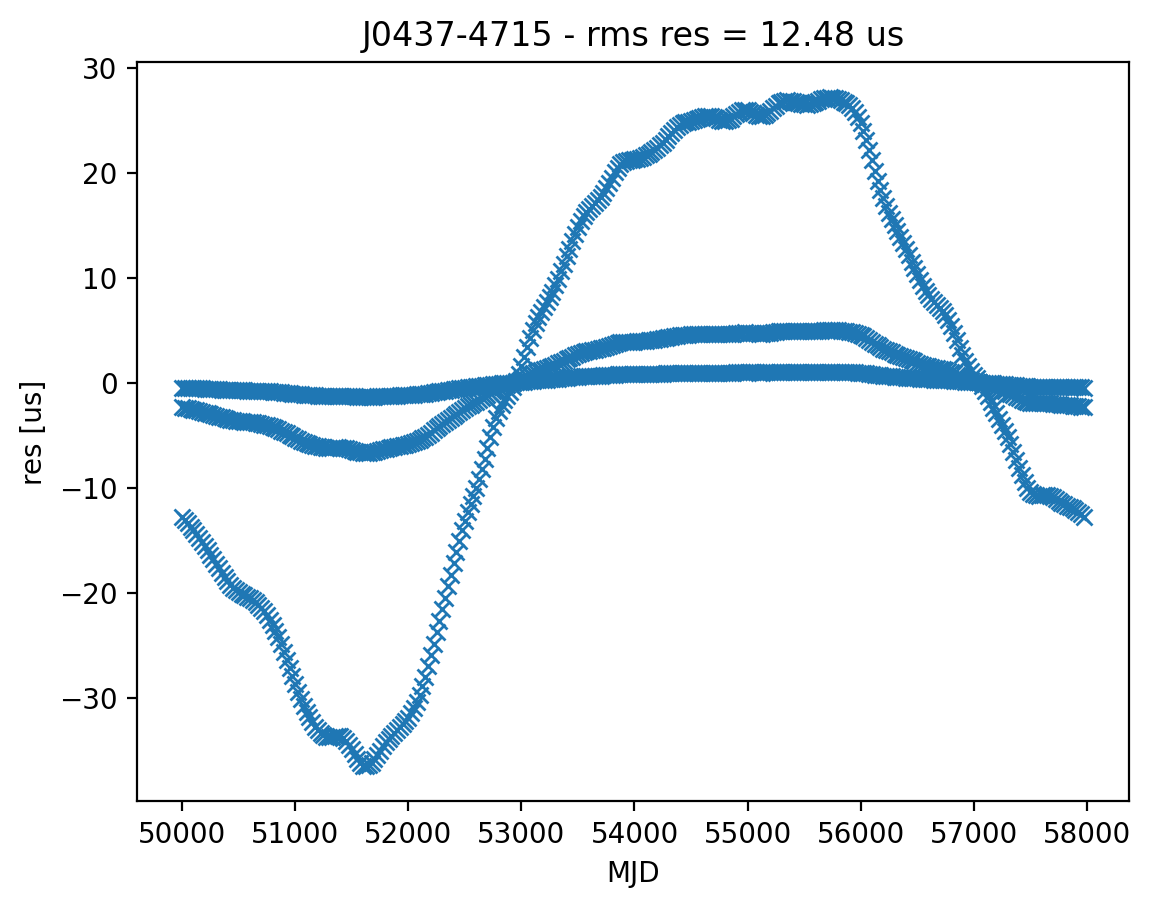

In [18]:
# Simulating dispersion measure
LT.make_ideal(base_psr)
add_dm(base_psr,2e-14,3.3)
LP.plotres(base_psr)

<div style = 'background-color:skyblue'> Which one do you think is the 600 MHz frequency, which is the 1400 MHz, which is the 3200 MHz? Why? </div>

What abut **chromatic noise**?

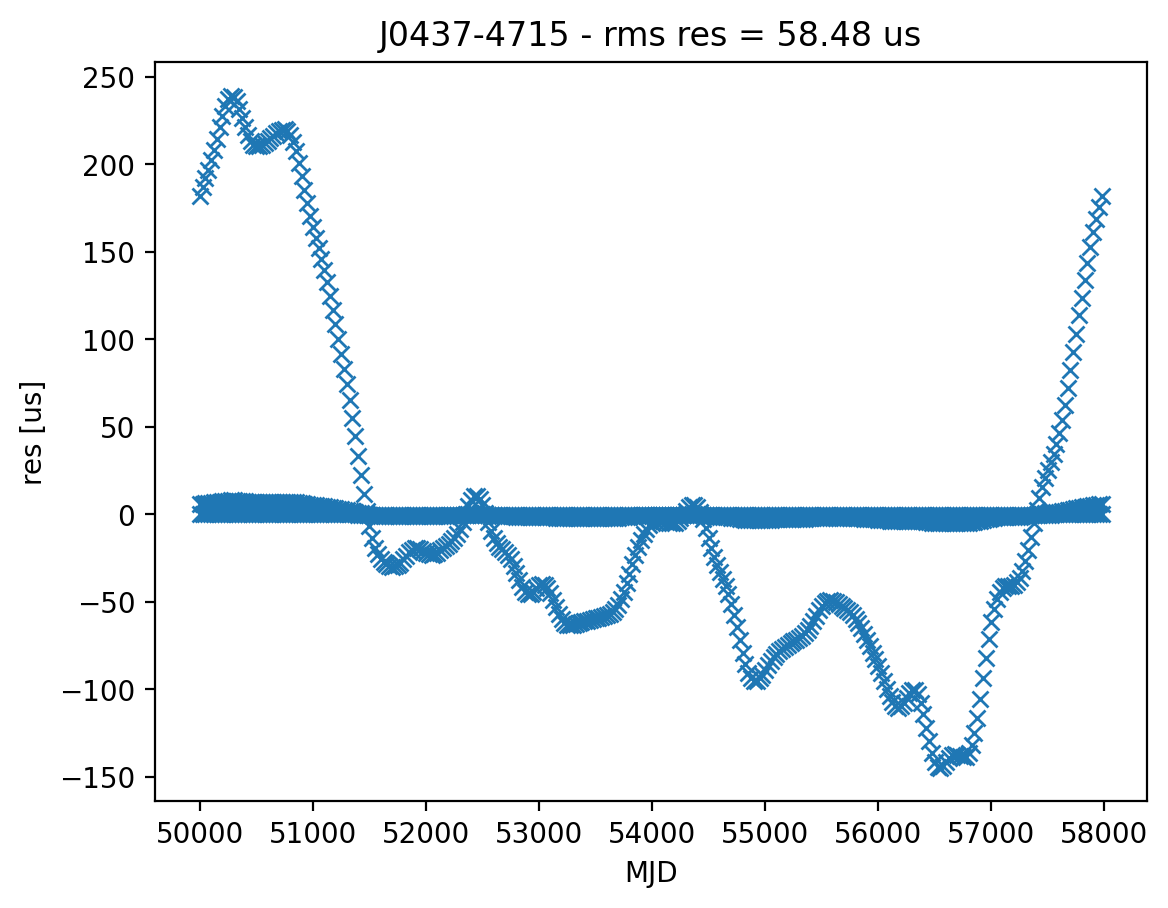

In [19]:
# Simulating chromatic noise
LT.make_ideal(base_psr)
add_ch(base_psr,5e-14,3, idx=-4)
LP.plotres(base_psr)

And **solar wind**?

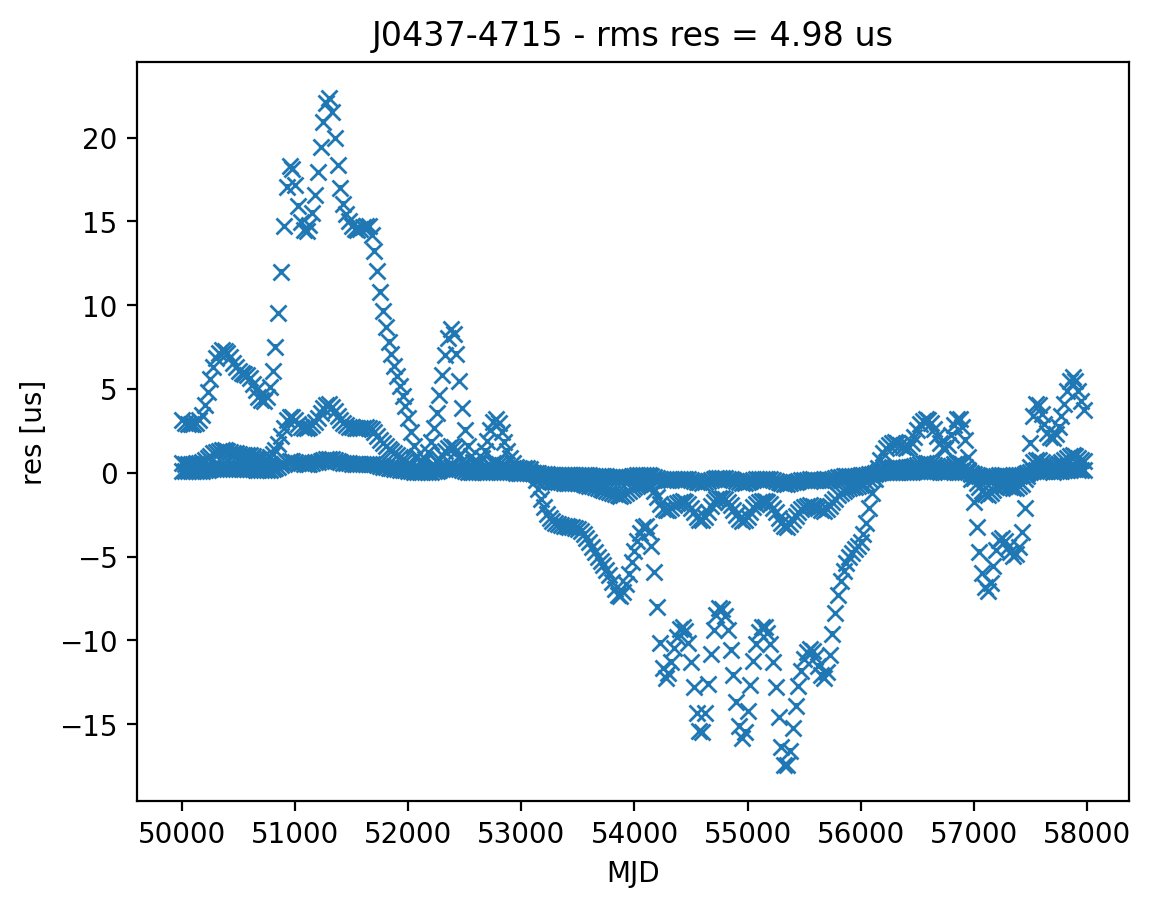

In [20]:
# Simulating solar wind
LT.make_ideal(base_psr)
add_sw(base_psr,5e-6,2)
LP.plotres(base_psr)

<div style = 'background-color:skyblue'> Why does solar wind look so different from  dispersion measure and chromatic noise </div>

We can also simulate a gravitational wave

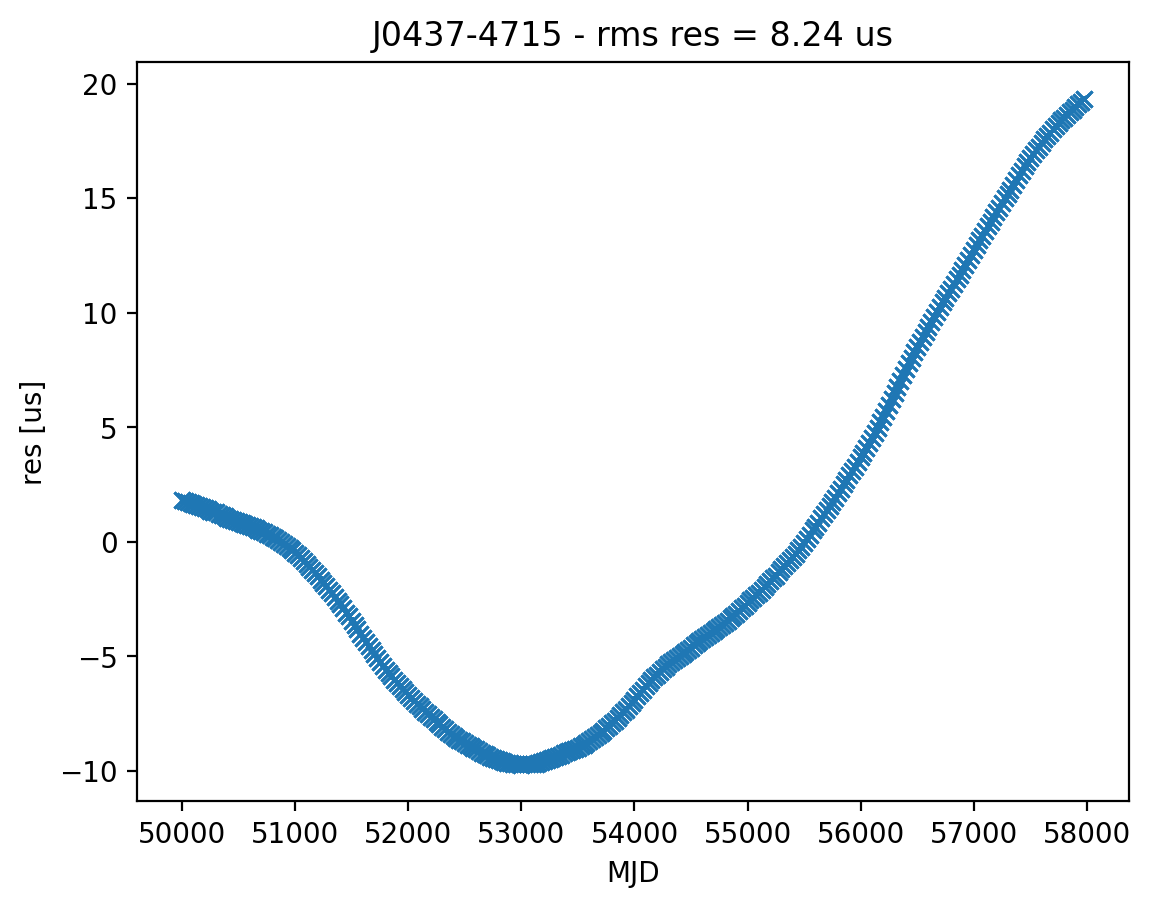

In [21]:
LT.make_ideal(base_psr)
LT.createGWB([base_psr], Amp=5e-15, gam=13./3., seed=12)
LP.plotres(base_psr)

---

We can also simulate an ideal realization of the timing model defined in a .par file, even without a corresponding .tim file. This involves specifying a new set of observation times and associated uncertainties. Additionally, we can define the observing frequencies, the observatory used, and any relevant flags. In this example, we will simulate observations at three different radio frequencies.

/fred/oz005/users/pulsar_workshop/valentina2/.conda/envs/ent15y/lib/python3.9/site-packages/numpy/core/getlimits.py:500: UserWarning: The value of the smallest subnormal for <class 'numpy.float64'> type is zero.
  setattr(self, word, getattr(machar, word).flat[0])
/fred/oz005/users/pulsar_workshop/valentina2/.conda/envs/ent15y/lib/python3.9/site-packages/numpy/core/getlimits.py:89: UserWarning: The value of the smallest subnormal for <class 'numpy.float64'> type is zero.
  return self._float_to_str(self.smallest_subnormal)
/fred/oz005/users/pulsar_workshop/valentina2/.conda/envs/ent15y/lib/python3.9/site-packages/numpy/core/getlimits.py:500: UserWarning: The value of the smallest subnormal for <class 'numpy.float32'> type is zero.
  setattr(self, word, getattr(machar, word).flat[0])
/fred/oz005/users/pulsar_workshop/valentina2/.conda/envs/ent15y/lib/python3.9/site-packages/numpy/core/getlimits.py:89: UserWarning: The value of the smallest subnormal for <class 'numpy.float32'> type is z

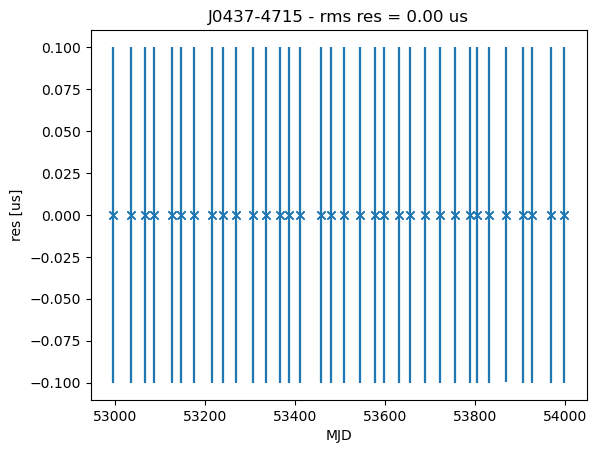

In [1]:
# import packages
import numpy as np
import libstempo as T
import libstempo.toasim as LT
import libstempo.plot as LP
import matplotlib.pyplot as plt
import scipy.constants as sc
import math
import os

datadir = '/fred/oz005/users/pulsar_workshop/valentina2/PTA_tutorials/data/'


# simulate from fake pulsar for 3 radio frequencies
obstimes = np.arange(53000, 54000, 30)
obstimes = (obstimes + np.random.uniform(-10, 10, 
            size=obstimes.shape)).astype(int) #beacuse we dont'always observe exactly every 30 days

# define the observation times for all frequencies
obstimes_600 = obstimes
obstimes_1400 = obstimes
obstimes_3200 = obstimes

# Combine TOAs into a single array
combined_obstimes = np.concatenate([obstimes_600, obstimes_1400, obstimes_3200])

# Corresponding frequencies and errors for each TOA
combined_freq = np.concatenate([
    np.full(len(obstimes_600), 600),
    np.full(len(obstimes_1400), 1400),
    np.full(len(obstimes_3200), 3200)
])
combined_toaerr = np.concatenate([
    np.full(len(obstimes_600), 0.1),
    np.full(len(obstimes_1400), 0.1),
    np.full(len(obstimes_3200), 0.1)
])

parfile = datadir + 'J0437-4715.par'
fake_psr = LT.fakepulsar(parfile=parfile, obstimes=combined_obstimes, 
                         toaerr=combined_toaerr, freq=combined_freq, observatory="pks", flags="-or pks")
LP.plotres(fake_psr)

Let's now inject some radiometer noise, timing noise and disperion measure.

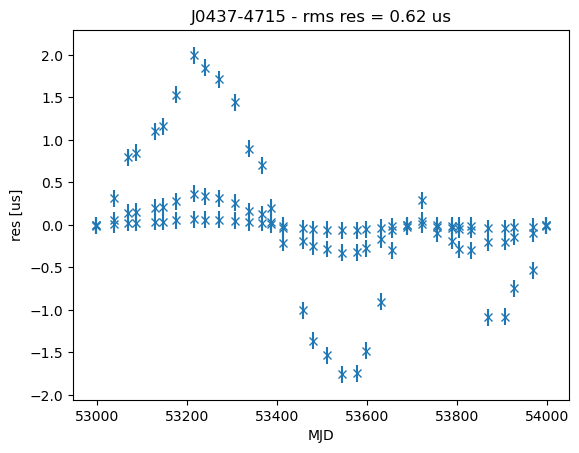

In [6]:
add_dm(fake_psr,2e-14,3.3)
LT.add_efac(base_psr,efac=1.0,seed=1234)
LT.add_rednoise(base_psr,7e-14,2.5)
LP.plotres(fake_psr)

Finally, we can save this simulated pulsar.

In [7]:
outdir = '/fred/oz002/vdimarco/PTA_tutorials/oudir/'
os.makedirs(outdir, exist_ok=True)
fake_psr.savepar(outdir + 'J0437-4715.par')
fake_psr.savetim(outdir + 'J0437-4715.tim')

[tempo2Util.C:396] Warning: [TIM1] Please place MODE flags in the parameter file 
[tempo2Util.C:401] Warning: [DUP1] duplicated warnings have been suppressed.


Results for PSR J0437-4715


RMS pre-fit residual = 0.000 (us), RMS post-fit residual = 0.622 (us)
Fit Chisq = 0	Chisqr/nfree = 0.00/0 = -nan	pre/post = 0
Number of fit parameters: 0
Number of points in fit = 0
Offset: 0 0 offset_e*sqrt(n) = 0 n = 0


PARAMETER       Pre-fit                   Post-fit                  Uncertainty   Difference   Fit
---------------------------------------------------------------------------------------------------
RAJ (rad)       1.20979058355726          1.20979058355726          0             0             N
RAJ (hms)       04:37:15.8146878          04:37:15.8146878          0             0            
DECJ (rad)      -0.824709874239124        -0.824709874239124        0             0             N
DECJ (dms)      -47:15:08.62242           -47:15:08.62242           0             0            


You can try now to simulate a different pulsar (there is a list of pulsars in this directory) <mark>/fred/oz005/users/pulsar_workshop/valentina2/PTA_tutorials/data.</mark>

- Can you find a pulsar that is not in the plane of the solar system and simulate the solar wind?
- What does a chromatic noise with a very shallow spectral index look like.
- If you simulate red noise and a gravitational wave with the same spectral index what do they look like. Can you distringuish between a gravitational wave and timing noise?